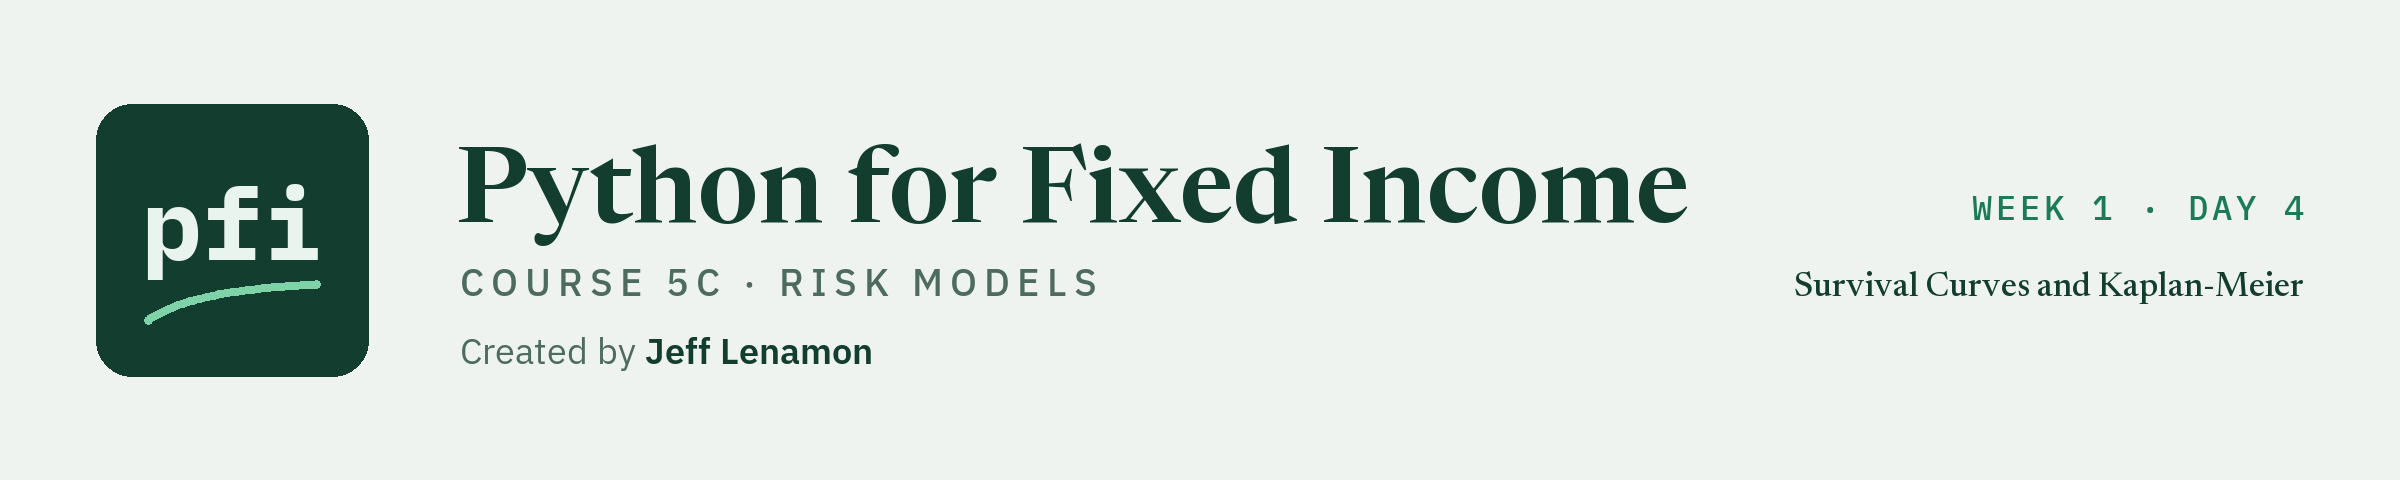

# Survival Curves and Kaplan-Meier

Week 1, Day 4. When firms default, not only whether: survival curves with censoring, Kaplan-Meier by hand and on the cohort, curves by rating, the log-rank test, and the hazard.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day4/04_survival_curves_and_kaplan_meier.ipynb)

Day 3 asked how many firms default in a year. Today asks how long a firm survives: the share of firms still free of default after 1, 5, or 10 years. That is a **survival curve**, and the trouble with drawing one is that most firms are never seen to default. Some leave the study, refinanced or called away; others are still going when the study ends. They are **censored**: we know they survived at least as long as we watched them, and nothing after. Today shows what goes wrong when they are dropped or counted as survivors, and how Kaplan-Meier uses them correctly.

* **The firms are synthetic.** `course5c_cohort.csv` is 4,000 invented firms followed in study years, not calendar years. Only the development years, 1 to 14, are used.
* **Names.** A curve is "survival in study years since entry" and a hazard is "the share at risk that defaulted". They are never a forecast of defaults, and never a statement about a real firm or a real rating.

Today you will:

1. Turn firm-years into one row per firm: the years watched, and whether the watch ended in a default.
2. Work Kaplan-Meier by hand on ten firms, then write it as a function (`kaplan_meier`).
3. See the bias when censored firms are dropped, or counted as survivors.
4. Fit the cohort's curve with statsmodels, with its confidence band, and draw curves by rating.
5. Test whether two curves differ with the log-rank test.
6. Read the hazard year by year, the cumulative hazard, and a flat hazard's curve beside the real one.
7. Turn an invented spread and recovery rate into a hazard with the credit triangle.

Q. Set up today's work folder: the thread settings, the seed, the cohort, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05c_risk_models/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scipy, statsmodels, or scikit-learn is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05c_risk_models/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5c_04_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["ratings.csv", "course5c_cohort.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5c_04_ko9w2c_0, in your temp folder
Data files from the data folder of the course repo: ratings.csv, course5c_cohort.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, unchanged. `riskkit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `riskkit.py` and `test_riskkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile riskkit.py
"""riskkit: risk models for a bond desk, built day by day in Course 5C.

Conventions, stated once:
- Money is in US$. Rate and spread moves are in bp. A default probability is a fraction a year: 0.02 is 2 percent.
- A loss is a positive number of US$. P&L is positive for a gain.
- Every random draw comes from a numpy Generator the caller passes in as rng. Nothing here seeds a generator or
  uses the legacy np.random functions, so one seed at the top of a notebook decides every draw.
- The inputs are the course's synthetic book, its synthetic cohort, or past data. Nothing here describes a real
  security or a real issuer.
"""
import math

import numpy as np
from scipy.stats import norm

import mlkit  # noqa: F401  (the past-only checks, used from day 5)


def mc_mean(draws) -> tuple[float, float]:
    """The Monte Carlo estimate of a mean, and its standard error.

    Input: draws, a 1-D array of independent trial outcomes: at least 2, none of them NaN.
    Output: (mean, standard error). The standard error is the sample standard deviation (ddof=1) over the
    square root of the number of draws: how far the mean of this many draws typically lands from the true mean.
    Raises ValueError for fewer than 2 draws, more than one dimension, or a NaN.
    """
    values = np.asarray(draws, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("draws must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("draws hold a NaN")
    return float(values.mean()), float(values.std(ddof=1) / math.sqrt(len(values)))


def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
    """How many independent trials put a Monte Carlo mean within half_width of the true mean, at this confidence.

    n = ceil((z * sd / half_width) ** 2), with z the two-sided normal quantile (1.96 at 0.95).
    Inputs: sd, the standard deviation of one trial, and half_width, in the same unit, both above 0; confidence
    strictly between 0 and 1.
    Output: the number of trials, a whole number.
    Raises ValueError for an sd or half_width that is not above 0, or a confidence outside (0, 1).
    """
    if sd <= 0 or half_width <= 0:
        raise ValueError("sd and half_width must be above 0")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1")
    z = norm.ppf(0.5 + confidence / 2)
    return math.ceil((z * sd / half_width) ** 2)


def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
    """n standard normal draws in antithetic pairs: n // 2 draws z, then their mirror images -z.

    Inputs: rng, a numpy Generator; n, a positive even number.
    Output: an array of n draws. Draw i and draw i + n // 2 are a pair (z and -z), so the draws' mean is 0 exactly.
    A pair is not two independent draws: average each pair before computing a standard error.
    Raises ValueError for an n that is odd or not above 0.
    """
    if n <= 0 or n % 2:
        raise ValueError("n must be a positive even number")
    half = rng.standard_normal(n // 2)
    return np.concatenate([half, -half])


import pandas as pd  # dated tables: the book's P&L by day
from scipy.stats import chi2  # the chi-squared distribution of Kupiec's test


def historical_pnl(book, rate_moves, spread_moves):
    """The book's P&L on each past day, had that day's rate and spread moves happened to today's book.

    For each bond and day: the rate move is the Treasury change at the bond's years to maturity, read off the curve
    by straight-line interpolation between the two nearest tenors (the first or last tenor beyond the ends); the
    spread move is the bond's OAS times the relative change in its spread index (the DTS approach). The P&L is
    minus market value x (duration x rate move + spread duration x spread move) / 10,000. First order only: no
    convexity, no carry, no roll down the curve.
    Inputs:
    - book: a DataFrame with one row per bond and the columns market_value (US$), duration, spread_duration, oas
      (bp), years_to_maturity, and spread_index (the name of a column of spread_moves).
    - rate_moves: a DataFrame of daily Treasury changes in bp, one row per date, one column per tenor in years.
    - spread_moves: a DataFrame of daily relative changes of each spread index (0.01 is 1 percent wider), on the
      same dates as rate_moves.
    Output: a DataFrame on those dates with the columns rates, spreads, and total, in US$.
    Raises ValueError for a missing book column, an unknown spread index, dates that differ, or a NaN in the moves.
    """
    needed = ["market_value", "duration", "spread_duration", "oas", "years_to_maturity", "spread_index"]
    missing = [name for name in needed if name not in book.columns]
    if missing:
        raise ValueError(f"book lacks the columns {missing}")
    unknown = sorted(set(book["spread_index"]) - set(spread_moves.columns))
    if unknown:
        raise ValueError(f"spread_moves has no column for the spread indexes {unknown}")
    if not rate_moves.index.equals(spread_moves.index):
        raise ValueError("rate_moves and spread_moves must be on the same dates")
    if rate_moves.isna().any().any() or spread_moves[list(set(book["spread_index"]))].isna().any().any():
        raise ValueError("the moves hold a NaN")
    tenors = np.asarray(rate_moves.columns, dtype=float)
    # interpolation is linear in the curve's values, so each bond's weight on each tenor is the curve 0 everywhere
    # but 1 at that tenor, read at the bond's maturity
    weights = np.column_stack([np.interp(book["years_to_maturity"], tenors, np.eye(len(tenors))[j])
                               for j in range(len(tenors))])
    bond_rate_moves = rate_moves.to_numpy() @ weights.T
    bond_spread_moves = spread_moves[book["spread_index"]].to_numpy() * book["oas"].to_numpy()
    rates = -(bond_rate_moves * (book["duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    spreads = -(bond_spread_moves * (book["spread_duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    return pd.DataFrame({"rates": rates, "spreads": spreads, "total": rates + spreads}, index=rate_moves.index)


def var_es(pnl, level: float = 0.99) -> tuple[float, float]:
    """The VaR and the expected shortfall of a sample of P&L, both as positive US$ losses.

    VaR at level (for example 0.99) is minus the (1 - level) quantile of the P&L, with linear interpolation between
    the two nearest values: Excel's PERCENTILE.INC. Expected shortfall is minus the mean P&L on the days at or below
    that quantile: the average loss on the days the loss is at least the VaR, so it is never below the VaR.
    Inputs: pnl, a 1-D array of at least 2 values in US$, a gain positive, none of them NaN; level strictly between
    0.5 and 1.
    Output: (VaR, expected shortfall), in US$.
    Raises ValueError for fewer than 2 values, more than one dimension, a NaN, or a level outside (0.5, 1).
    """
    values = np.asarray(pnl, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("pnl must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("pnl holds a NaN")
    if not 0.5 < level < 1:
        raise ValueError("level must be between 0.5 and 1")
    cutoff = float(np.quantile(values, 1 - level))
    return -cutoff, -float(values[values <= cutoff].mean())


def kupiec_pof(exceptions: int, n: int, level: float) -> tuple[float, float]:
    """Kupiec's proportion-of-failures test: is the count of VaR exceptions in line with the VaR's level?

    Under a correct VaR each of n days is an exception with chance p = 1 - level, independently. The statistic is
    the likelihood ratio LR = -2 ln[(1 - p)^(n - x) p^x] + 2 ln[(1 - x/n)^(n - x) (x/n)^x] for x exceptions, which
    is close to a chi-squared with 1 degree of freedom when the VaR is right.
    Inputs: exceptions, a whole number from 0 to n; n, the number of days tested, above 0; level strictly between
    0 and 1.
    Output: (LR, p-value). A small p-value says the count is hard to square with the level: too many exceptions,
    or too few.
    Raises ValueError for a count outside 0 to n, an n that is not above 0, or a level outside (0, 1).
    """
    if n <= 0 or not 0 <= exceptions <= n:
        raise ValueError("exceptions must be between 0 and n, and n above 0")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    p, x = 1 - level, exceptions
    observed = x / n

    def log_likelihood(q: float) -> float:
        # x ln q + (n - x) ln(1 - q), with 0 ln 0 taken as 0
        return (x * math.log(q) if x else 0.0) + ((n - x) * math.log(1 - q) if n - x else 0.0)

    lr = max(0.0, -2 * (log_likelihood(p) - log_likelihood(observed)))
    return lr, float(chi2.sf(lr, 1))


def one_factor_defaults(pd, rho: float, n_sims: int, rng: np.random.Generator) -> np.ndarray:
    """Simulated defaults of a group of bonds whose defaults move together through one common factor.

    In each scenario every bond's asset value is sqrt(rho) x Z + sqrt(1 - rho) x e, with Z one standard normal draw
    shared by every bond (the state of the economy) and e a standard normal draw of the bond's own. A bond defaults
    when its asset value is below the normal quantile of its default probability, so each bond still defaults with
    exactly its own probability, and rho sets how often they default together.
    Inputs: pd, a number or a 1-D array of annual default probabilities, one per bond, each strictly between 0 and
    1; rho, the asset correlation, from 0 up to (not including) 1; n_sims, the number of scenarios, above 0; rng, a
    numpy Generator.
    Output: a boolean array of shape (n_sims, number of bonds): True where that bond defaulted in that scenario.
    Raises ValueError for a pd outside (0, 1), a rho outside [0, 1), or an n_sims that is not above 0.
    """
    probabilities = np.atleast_1d(np.asarray(pd, dtype=float))
    if probabilities.ndim != 1 or not ((probabilities > 0) & (probabilities < 1)).all():
        raise ValueError("pd must be a number or a 1-D array, each strictly between 0 and 1")
    if not 0 <= rho < 1:
        raise ValueError("rho must be from 0 up to 1")
    if n_sims <= 0:
        raise ValueError("n_sims must be above 0")
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(probabilities)))
    assets = math.sqrt(rho) * common + math.sqrt(1 - rho) * own
    return assets < norm.ppf(probabilities)


def vasicek_quantile(pd: float, rho: float, q: float) -> float:
    """The default rate of a very large group of alike bonds that is not exceeded with probability q (Vasicek).

    N((N^-1(pd) + sqrt(rho) x N^-1(q)) / sqrt(1 - rho)), N the standard normal distribution: the one-factor model's
    default rate when the common factor sits at its own q quantile on the bad side. Exact only in the limit of
    many bonds, each with the same pd and rho.
    Inputs: pd, rho, and q, each strictly between 0 and 1.
    Output: a default rate between 0 and 1.
    Raises ValueError for any input outside (0, 1).
    """
    for name, value in (("pd", pd), ("rho", rho), ("q", q)):
        if not 0 < value < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1")
    return float(norm.cdf((norm.ppf(pd) + math.sqrt(rho) * norm.ppf(q)) / math.sqrt(1 - rho)))


def loss_distribution(book, defaults, lgd) -> np.ndarray:
    """The credit loss of the book in each simulated scenario, in US$.

    A defaulted bond loses its market value (its exposure at default) times its loss given default; a bond that did
    not default loses nothing.
    Inputs: book, a DataFrame with a market_value column (US$), one row per bond; defaults, a boolean array of shape
    (scenarios, bonds), as one_factor_defaults returns; lgd, the loss given default as a share between 0 and 1: a
    number, one per bond, or one per scenario and bond.
    Output: an array of one loss per scenario, in US$ (positive is a loss).
    Raises ValueError for defaults whose number of columns is not the number of bonds, or an lgd outside [0, 1].
    """
    hits = np.asarray(defaults, dtype=bool)
    exposure = book["market_value"].to_numpy(dtype=float)
    if hits.ndim != 2 or hits.shape[1] != len(exposure):
        raise ValueError("defaults must have one column per bond of the book")
    shares = np.asarray(lgd, dtype=float)
    if ((shares < 0) | (shares > 1)).any():
        raise ValueError("lgd must be between 0 and 1")
    return (hits * shares * exposure).sum(axis=1)

Writing riskkit.py


In [5]:
%%writefile test_riskkit.py
"""Tests for riskkit.py. Small seeded arrays only; no data file is read."""
import math

import numpy as np
import pytest

import riskkit


def test_mc_mean_hand():
    # mean 2.5; sample standard deviation sqrt(5/3); standard error that over sqrt(4)
    mean, se = riskkit.mc_mean([1.0, 2.0, 3.0, 4.0])
    assert mean == 2.5
    assert se == pytest.approx(math.sqrt(5 / 3) / 2, rel=1e-12)


def test_mc_mean_refuses():
    with pytest.raises(ValueError, match="at least 2"):
        riskkit.mc_mean([1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.mc_mean([1.0, float("nan"), 3.0])


def test_mc_mean_covers_a_known_mean():
    # 2 percent default, US$600,000 lost: the true mean is US$12,000; 40,000 draws land within 4 standard errors
    rng = np.random.default_rng(42)
    losses = np.where(rng.random(40_000) < 0.02, 600_000.0, 0.0)
    mean, se = riskkit.mc_mean(losses)
    assert abs(mean - 12_000.0) < 4 * se


def test_trials_needed_hand():
    # z at 95 percent is 1.959964; (1.959964 * 10 / 1) ** 2 = 384.15, so 385 trials
    assert riskkit.trials_needed(10.0, 1.0) == 385
    # halving the half-width takes four times the trials, give or take the rounding up
    assert riskkit.trials_needed(10.0, 0.5) == 1_537
    with pytest.raises(ValueError, match="above 0"):
        riskkit.trials_needed(10.0, 0.0)
    with pytest.raises(ValueError, match="between 0 and 1"):
        riskkit.trials_needed(10.0, 1.0, confidence=1.0)


def test_antithetic_normals_pairs():
    draws = riskkit.antithetic_normals(np.random.default_rng(42), 10)
    assert len(draws) == 10
    assert np.array_equal(draws[5:], -draws[:5])
    assert draws.mean() == 0.0
    with pytest.raises(ValueError, match="even"):
        riskkit.antithetic_normals(np.random.default_rng(42), 7)


def test_antithetic_normals_same_seed_same_draws():
    first = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    second = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    assert np.array_equal(first, second)


import pandas as pd


def _one_bond(years):
    return pd.DataFrame({"market_value": [1_000_000.0], "duration": [5.0], "spread_duration": [5.0], "oas": [100.0],
                         "years_to_maturity": [years], "spread_index": ["ig"]})


def test_historical_pnl_hand():
    # 4 years sits halfway between the 3 and 5 year tenors: a 15 bp move, and 10 percent of 100 bp is 10 bp
    dates = pd.to_datetime(["2020-01-02"])
    rates = pd.DataFrame({3.0: [10.0], 5.0: [20.0]}, index=dates)
    spreads = pd.DataFrame({"ig": [0.10]}, index=dates)
    pnl = riskkit.historical_pnl(_one_bond(4.0), rates, spreads)
    assert pnl.loc[dates[0], "rates"] == pytest.approx(-7_500.0, rel=1e-12)
    assert pnl.loc[dates[0], "spreads"] == pytest.approx(-5_000.0, rel=1e-12)
    assert pnl.loc[dates[0], "total"] == pytest.approx(-12_500.0, rel=1e-12)
    # beyond the last tenor the last tenor's move is used
    assert riskkit.historical_pnl(_one_bond(8.0), rates, spreads).loc[dates[0], "rates"] == pytest.approx(-10_000.0)


def test_historical_pnl_refuses():
    dates = pd.to_datetime(["2020-01-02", "2020-01-03"])
    rates = pd.DataFrame({3.0: [10.0, 1.0], 5.0: [20.0, 2.0]}, index=dates)
    with pytest.raises(ValueError, match="same dates"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"ig": [0.1]}, index=dates[:1]))
    with pytest.raises(ValueError, match="no column"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"hy": [0.1, 0.2]}, index=dates))
    with pytest.raises(ValueError, match="NaN"):
        riskkit.historical_pnl(_one_bond(4.0), rates.where(rates > 1), pd.DataFrame({"ig": [0.1, 0.2]}, index=dates))


def test_var_es_hand():
    # losses of 1 to 100: the 5 percent quantile of the P&L sits 4.95 of the way from -100 to -99, so VaR 95.05;
    # the days at or below it lose 100, 99, 98, 97, and 96, an average of 98
    var, es = riskkit.var_es(-np.arange(1.0, 101.0), 0.95)
    assert var == pytest.approx(95.05, rel=1e-12)
    assert es == pytest.approx(98.0, rel=1e-12)


def test_var_es_shortfall_at_least_var():
    pnl = np.random.default_rng(42).standard_t(4, 5_000)
    for level in (0.95, 0.99):
        var, es = riskkit.var_es(pnl, level)
        assert es >= var > 0


def test_var_es_refuses():
    with pytest.raises(ValueError, match="NaN"):
        riskkit.var_es([1.0, float("nan"), -2.0])
    with pytest.raises(ValueError, match="between 0.5 and 1"):
        riskkit.var_es([1.0, -2.0, 3.0], 0.01)


def test_kupiec_pof_hand():
    # exactly the expected count: the statistic is 0 and the p-value 1
    assert riskkit.kupiec_pof(10, 1_000, 0.99) == pytest.approx((0.0, 1.0))
    # 5 exceptions in 250 days at 99 percent, against the formula written out
    x, n, p = 5, 250, 0.01
    lr = -2 * ((n - x) * math.log(1 - p) + x * math.log(p) - (n - x) * math.log(1 - x / n) - x * math.log(x / n))
    assert riskkit.kupiec_pof(x, n, 0.99)[0] == pytest.approx(lr, rel=1e-12)
    # no exception at all is too few for a long sample
    assert riskkit.kupiec_pof(0, 2_000, 0.99)[1] < 0.01


def test_kupiec_pof_refuses():
    with pytest.raises(ValueError, match="between 0 and n"):
        riskkit.kupiec_pof(11, 10, 0.99)


from scipy.stats import norm


def test_one_factor_defaults_shape_and_rate():
    defaults = riskkit.one_factor_defaults([0.02, 0.10], 0.3, 50_000, np.random.default_rng(42))
    assert defaults.shape == (50_000, 2) and defaults.dtype == bool
    # each bond still defaults with its own probability, whatever rho is
    assert defaults[:, 0].mean() == pytest.approx(0.02, abs=0.003)
    assert defaults[:, 1].mean() == pytest.approx(0.10, abs=0.006)


def test_one_factor_defaults_correlation_fattens_the_count():
    # 100 alike bonds: the mean count stays at 2, the chance of 10 or more grows with rho
    rng_a, rng_b = np.random.default_rng(42).spawn(2)
    independent = riskkit.one_factor_defaults(np.full(100, 0.02), 0.0, 20_000, rng_a).sum(axis=1)
    correlated = riskkit.one_factor_defaults(np.full(100, 0.02), 0.3, 20_000, rng_b).sum(axis=1)
    assert abs(independent.mean() - correlated.mean()) < 0.2
    assert (correlated >= 10).mean() > 10 * max((independent >= 10).mean(), 1e-4)


def test_one_factor_defaults_refuses():
    with pytest.raises(ValueError, match="strictly between 0 and 1"):
        riskkit.one_factor_defaults([0.02, 0.0], 0.2, 10, np.random.default_rng(42))
    with pytest.raises(ValueError, match="rho"):
        riskkit.one_factor_defaults(0.02, 1.0, 10, np.random.default_rng(42))


def test_vasicek_quantile_hand():
    # at q = 0.5 the common factor sits at 0: N(N^-1(pd) / sqrt(1 - rho))
    assert riskkit.vasicek_quantile(0.02, 0.2, 0.5) == pytest.approx(norm.cdf(norm.ppf(0.02) / math.sqrt(0.8)), rel=1e-12)
    # a rho near 0 gives back pd at any q
    assert riskkit.vasicek_quantile(0.02, 1e-12, 0.999) == pytest.approx(0.02, rel=1e-4)
    with pytest.raises(ValueError, match="rho"):
        riskkit.vasicek_quantile(0.02, 0.0, 0.999)


def test_loss_distribution_hand():
    book = pd.DataFrame({"market_value": [100.0, 200.0, 300.0]})
    defaults = np.array([[True, False, True], [False, False, False]])
    # scenario 1 loses 60 percent of 100 and of 300; scenario 2 loses nothing
    assert riskkit.loss_distribution(book, defaults, 0.6).tolist() == pytest.approx([240.0, 0.0])
    assert riskkit.loss_distribution(book, defaults, [0.5, 0.6, 0.7]).tolist() == pytest.approx([260.0, 0.0])
    with pytest.raises(ValueError, match="one column per bond"):
        riskkit.loss_distribution(book, defaults[:, :2], 0.6)

Writing test_riskkit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import riskkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(riskkit)

# the functions defined in riskkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(riskkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "riskkit" and not name.startswith("_")]
print(f"riskkit functions: {functions}")

riskkit functions: ['mc_mean', 'trials_needed', 'antithetic_normals', 'historical_pnl', 'var_es', 'kupiec_pof', 'one_factor_defaults', 'vasicek_quantile', 'loss_distribution']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is the course's own. It writes `riskkit.py` and `test_riskkit.py` as day 3 left them.

## 4.1 Survival, Hazard, and Censoring

**How it works.** The **survival function** S(t) is the share of firms still free of default t years after they entered. The **hazard** in year t is the share of the firms still at risk at the start of year t that default during it. The two are tied: survival past t is the product of (1 minus the hazard) over every year up to t. A firm is **censored** when its watch ends without a default: it left the study, or the study ended. A censored firm still tells us something: it survived every year it was watched. The settings are how time is measured (years since entry) and what counts as the event (a default, and nothing else). What comes out is one row per firm: its time and its event.

Q. Turn the cohort's firm-year rows into one row per firm.

In [9]:
# the synthetic cohort: invented firms with ids only, in study years; the development years 1 to 14 only
cohort = pd.read_csv("course5c_cohort.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END]

# one row per firm: the years it was watched, how its last year ended, and its rating when it entered
firms = development.groupby("firm_id").agg(years=("years_since_entry", "max"), defaulted=("default", "max"),
                                           exited=("exit", "max"), entry_rating=("rating", "first"))
GROUPS = {"AAA": "investment grade", "AA": "investment grade", "A": "investment grade", "BBB": "investment grade",
          "BB": "BB", "B": "B", "CCC": "CCC"}
firms["entry_bucket"] = firms["entry_rating"].map(ratings["bucket"])
firms["group"] = firms["entry_bucket"].map(GROUPS)
print(f"{len(firms):,} invented firms entered by study year {DEVELOPMENT_END}")
print(firms.head().to_string())

3,504 invented firms entered by study year 14
         years  defaulted  exited entry_rating entry_bucket             group
firm_id                                                                      
F0001        9          0       1           BB           BB                BB
F0002        2          1       0            B            B                 B
F0003       14          0       0          AA-           AA  investment grade
F0004        4          0       1           B+            B                 B
F0005       14          0       0           A-            A  investment grade


* 3,504 firms entered by study year 14. A firm's `years` is the number of development years it was watched, counted from its entry.

Q. How did each firm's watch end?

In [10]:
# how each firm's watch ended: a default, or one of two kinds of censoring
outcomes = pd.DataFrame({
    "firms": [int(firms["defaulted"].sum()), int(firms["exited"].sum()),
              int(((firms["defaulted"] == 0) & (firms["exited"] == 0)).sum())],
    "counted as": ["an event", "censored", "censored"],
}, index=pd.Index(["defaulted", "left the study (refinanced or called away)", "still at risk at the end of year 14"],
                  name="how the watch ended"))
outcomes["share of firms (percent)"] = 100 * outcomes["firms"] / len(firms)
print(outcomes.round(1).to_string())

                                            firms counted as  share of firms (percent)
how the watch ended                                                                   
defaulted                                     345   an event                       9.8
left the study (refinanced or called away)   1231   censored                      35.1
still at risk at the end of year 14          1928   censored                      55.0


In [11]:
plotkit.styled(outcomes, [], "How the watch of each synthetic firm ended, development study years 1 to 14", fmt="{:,.1f}")

,firms,counted as,share of firms (percent)
how the watch ended,,,
defaulted,345,an event,9.8
left the study (refinanced or called away),"1,231",censored,35.1
still at risk at the end of year 14,"1,928",censored,55.0


* Only 345 firms were seen to default. 90% are censored: 1,231 left the study and 1,928 were still at risk when year 14 ended. A survival curve that cannot use those firms throws away most of the data.

## 4.2 Kaplan-Meier by Hand

**How it works.** Kaplan-Meier walks through the distinct times in order. At each one it counts the firms **at risk** (watched for at least that long), the defaults at that time, and the firms censored at that time. The share surviving that time is 1 minus defaults over at risk, and the curve is the running product of those shares. A censored firm counts as at risk up to its last year and then leaves the count; it is never a default. The settings are none beyond the data. What comes out is a step curve that drops only at a default, and drops more when fewer firms are left at risk.

Q. Take ten firms, three that defaulted and seven that did not, and lay out their years.

In [12]:
# ten firms to work by hand: three that defaulted and seven that did not, drawn with a generator from SEED
rng = np.random.default_rng(SEED)
picked = np.concatenate([rng.choice(firms.index[firms["defaulted"] == 1], 3, replace=False),
                         rng.choice(firms.index[firms["defaulted"] == 0], 7, replace=False)])
ten = firms.loc[picked, ["years", "defaulted"]].sort_values(["years", "defaulted"], ascending=[True, False])
print(ten.to_string())

         years  defaulted
firm_id                  
F3024        1          0
F0313        1          0
F3422        1          0
F0340        1          0
F1882        3          1
F0248        3          1
F2238        5          1
F2479        5          0
F1889        7          0
F0735       12          0


Q. Work the curve by hand: at risk, defaults, censored, and the running product.

In [13]:
# Kaplan-Meier by hand: at each distinct number of years, who is at risk, who defaults, and the running product
rows, survival = [], 1.0
for t in sorted(ten["years"].unique()):
    at_risk = int((ten["years"] >= t).sum())
    defaults = int(((ten["years"] == t) & (ten["defaulted"] == 1)).sum())
    censored = int(((ten["years"] == t) & (ten["defaulted"] == 0)).sum())
    survival *= 1 - defaults / at_risk
    rows.append({"years": int(t), "at risk": at_risk, "defaults": defaults, "censored": censored,
                 "share surviving the year": 1 - defaults / at_risk, "survival": survival})
hand = pd.DataFrame(rows).set_index("years")
print(hand.round(4).to_string())

       at risk  defaults  censored  share surviving the year  survival
years                                                                 
1           10         0         4                    1.0000    1.0000
3            6         2         0                    0.6667    0.6667
5            4         1         1                    0.7500    0.5000
7            2         0         1                    1.0000    0.5000
12           1         0         1                    1.0000    0.5000


In [14]:
plotkit.styled(hand, ["survival"], "Kaplan-Meier by hand on ten synthetic firms", fmt="{:,.4f}")

,at risk,defaults,censored,share surviving the year,survival
years,,,,,
1,10,0,4,1.0000,1.0000
3,6,2,0,0.6667,0.6667
5,4,1,1,0.7500,0.5000
7,2,0,1,1.0000,0.5000
12,1,0,1,1.0000,0.5000


* Read one row at a time. The at-risk count falls by every firm that left before that row's year, default or not, so a censored firm makes later defaults count for more. The curve ends at 0.5000. Ignoring time altogether, 3 defaults in 10 firms would say 0.7; the hand table is lower because some firms were not watched long enough to show whether they would last.

Q. Add `kaplan_meier` to `riskkit.py`. Read the docstring first.

In [15]:
%%writefile -a riskkit.py


def kaplan_meier(time, event):
    """The Kaplan-Meier survival curve of a group observed for different lengths of time.

    Each subject is followed for time periods and either has the event at the end (event 1: here, a default) or is
    censored (event 0): it left the study, or the study ended, with no event seen. At each distinct time t, the
    subjects at risk are those followed for at least t; the curve multiplies, from the first time to t, the share
    of those at risk that did not have the event: S(t) = product of (1 - events / at risk). A censored subject counts
    as at risk up to and including its last time, and is never counted as an event.
    Inputs: time, a 1-D array of observed lengths (years, for example), each above 0; event, a 1-D array of the same
    length holding 1 for an event and 0 for censored.
    Output: a DataFrame with one row per distinct time, in order, and the columns at_risk, events, censored, and
    survival (the share expected to be event-free past that time).
    Raises ValueError for arrays of different lengths, a time that is not above 0, a NaN, or an event other than 0
    or 1.
    """
    times = np.asarray(time, dtype=float)
    events = np.asarray(event, dtype=float)
    if times.ndim != 1 or times.shape != events.shape or len(times) == 0:
        raise ValueError("time and event must be 1-D arrays of the same length, not empty")
    if np.isnan(times).any() or np.isnan(events).any():
        raise ValueError("time or event holds a NaN")
    if (times <= 0).any():
        raise ValueError("every time must be above 0")
    if not np.isin(events, (0, 1)).all():
        raise ValueError("event must hold only 0 and 1")
    distinct = np.unique(times)
    at_risk = np.array([(times >= t).sum() for t in distinct])
    had_event = np.array([((times == t) & (events == 1)).sum() for t in distinct])
    censored = np.array([((times == t) & (events == 0)).sum() for t in distinct])
    survival = np.cumprod(1 - had_event / at_risk)
    return pd.DataFrame({"at_risk": at_risk, "events": had_event, "censored": censored, "survival": survival},
                        index=pd.Index(distinct, name="time"))

Appending to riskkit.py


* The docstring says the one rule that matters: a censored subject counts as at risk up to and including its last time, and is never an event.

In [16]:
%%writefile -a test_riskkit.py


def test_kaplan_meier_hand():
    # six subjects: events at 1 and 3, censored at 2, 3, 4, and 4
    table = riskkit.kaplan_meier([1, 2, 3, 3, 4, 4], [1, 0, 1, 0, 0, 0])
    assert table.index.tolist() == [1.0, 2.0, 3.0, 4.0]
    assert table["at_risk"].tolist() == [6, 5, 4, 2]
    assert table["events"].tolist() == [1, 0, 1, 0]
    assert table["censored"].tolist() == [0, 1, 1, 2]
    # 5/6 after time 1, unchanged at 2 (a censoring is not an event), then times 3/4 at time 3
    assert table["survival"].tolist() == pytest.approx([5 / 6, 5 / 6, 5 / 6 * 3 / 4, 5 / 6 * 3 / 4])


def test_kaplan_meier_without_censoring_is_the_plain_share():
    # with no censoring, survival past t is simply the share still event-free
    time = np.array([1, 2, 2, 3, 5])
    table = riskkit.kaplan_meier(time, np.ones(5))
    assert table["survival"].tolist() == pytest.approx([0.8, 0.4, 0.2, 0.0])


def test_kaplan_meier_refuses():
    with pytest.raises(ValueError, match="same length"):
        riskkit.kaplan_meier([1, 2], [1])
    with pytest.raises(ValueError, match="above 0"):
        riskkit.kaplan_meier([0, 2], [1, 0])
    with pytest.raises(ValueError, match="only 0 and 1"):
        riskkit.kaplan_meier([1, 2], [1, 2])

Appending to test_riskkit.py


In [17]:
importlib.reload(riskkit)
print(f"kaplan_meier in riskkit: {hasattr(riskkit, 'kaplan_meier')}")

kaplan_meier in riskkit: True


In [18]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................                                                    [100%]
21 passed in 1.80s



* `21 passed`: day 3's 18 and today's 3. `test_kaplan_meier_hand` checks a censoring at time 2 that leaves the curve flat, and the second test that with no censoring the curve is the plain share.

Q. Does the module agree with the hand table?

In [19]:
# the module's table on the same ten firms
ten_table = riskkit.kaplan_meier(ten["years"], ten["defaulted"])
print(ten_table.round(4).to_string())
print(f"same survival as the hand table: {np.allclose(ten_table['survival'], hand['survival'])}")

      at_risk  events  censored  survival
time                                     
1.0        10       0         4    1.0000
3.0         6       2         0    0.6667
5.0         4       1         1    0.5000
7.0         2       0         1    0.5000
12.0        1       0         1    0.5000
same survival as the hand table: True


## 4.3 Why Censoring Matters

**How it works.** There are two easy ways to avoid censoring, and both are wrong. **Dropping** each firm censored before year t treats it as if it had never existed; it removes survivors only, so the share that defaulted is too high and the curve too low. **Counting censored firms as survivors** to year t assumes every firm that left would have lasted; it keeps survivors nobody watched, so the curve is too high. Kaplan-Meier uses each censored firm for exactly the years it was watched. The setting is how censoring is handled. What comes out is three curves from the same firms.

Q. Compute survival past each year all three ways.

In [20]:
# survival past each number of years, three ways: two that mishandle censored firms, and Kaplan-Meier
km = riskkit.kaplan_meier(firms["years"], firms["defaulted"])
years_grid = np.arange(1, 15)
defaulted_by = {t: int(((firms["defaulted"] == 1) & (firms["years"] <= t)).sum()) for t in years_grid}
comparison = pd.DataFrame({
    # wrong 1: drop each firm censored before t, as if it had never existed
    "dropping censored firms": [1 - defaulted_by[t] / int(((firms["defaulted"] == 1) | (firms["years"] >= t)).sum())
                                for t in years_grid],
    # wrong 2: count each censored firm as a survivor to t, whether it was watched that long or not
    "counting them as survivors": [1 - defaulted_by[t] / len(firms) for t in years_grid],
    "Kaplan-Meier": km["survival"].reindex(years_grid).to_numpy(),
}, index=pd.Index(years_grid, name="years since entry"))
print(comparison.loc[[1, 5, 10, 14]].round(4).to_string())

                   dropping censored firms  counting them as survivors  Kaplan-Meier
years since entry                                                                   
1                                   0.9823                      0.9823        0.9823
5                                   0.8628                      0.9229        0.8996
10                                  0.6249                      0.9035        0.8359
14                                  0.1727                      0.9015        0.8070


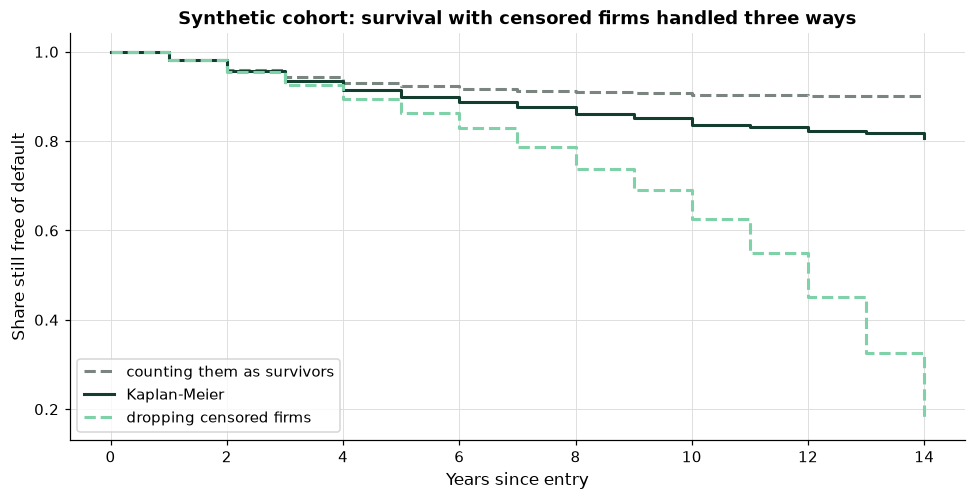

In [21]:
# every curve starts at 1 at year 0 and steps down at the end of each year with a default
curves = pd.concat([pd.DataFrame(1.0, index=[0], columns=comparison.columns), comparison])
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for column, colour, style in [("counting them as survivors", plotkit.GREY, "--"), ("Kaplan-Meier", plotkit.GREEN_DARK, "-"),
                              ("dropping censored firms", plotkit.GREEN_LIGHT, "--")]:
    ax.step(curves.index, curves[column], where="post", color=colour, linestyle=style, linewidth=2, label=column)
ax.set_xlabel("Years since entry")
ax.set_ylabel("Share still free of default")
ax.set_title("Synthetic cohort: survival with censored firms handled three ways")
ax.legend(loc="lower left")
plt.show()

* How to read it: all three start together, because in year 1 every firm was watched. They part as censoring builds up. Past 10 years, Kaplan-Meier says 83.6% of firms are still free of default; dropping the censored firms says 62.5%, and counting them as survivors says 90.4%. Neither wrong curve is a little off: each is off by more than any sampling error in the cohort.

In [22]:
plotkit.styled(comparison.loc[[1, 2, 5, 10, 14]], ["Kaplan-Meier"], "Survival past t years: two ways that mishandle censoring, "
               "and Kaplan-Meier", fmt="{:,.4f}")

,dropping censored firms,counting them as survivors,Kaplan-Meier
years since entry,,,
1,0.9823,0.9823,0.9823
2,0.9538,0.9603,0.9566
5,0.8628,0.9229,0.8996
10,0.6249,0.9035,0.8359
14,0.1727,0.9015,0.8070


## 4.4 The Cohort's Curve and Curves by Rating

**How it works.** statsmodels' `SurvfuncRight` computes the same Kaplan-Meier curve and adds **Greenwood's standard error** at each time, from which a 95 percent band is the curve plus and minus 1.96 standard errors. The band widens as fewer firms remain at risk. Splitting the firms by their rating at entry gives one curve per group. The settings are the time, the event, and the group. What comes out is a curve with its band for each group.

Q. Fit the cohort's curve with statsmodels, and compare with the module.

In [23]:
from statsmodels.duration.survfunc import SurvfuncRight

# statsmodels' Kaplan-Meier on the same firms, with Greenwood's standard error at each time
sf = SurvfuncRight(firms["years"], firms["defaulted"])
fitted = pd.DataFrame({"survival": sf.surv_prob, "standard error": sf.surv_prob_se, "at risk": sf.n_risk},
                      index=pd.Index(sf.surv_times, name="years"))
print(f"largest gap to riskkit.kaplan_meier: {np.abs(fitted['survival'].to_numpy() - km['survival'].to_numpy()).max():.1e}")
print(fitted.loc[[1, 5, 10, 14]].round(4).to_string())

largest gap to riskkit.kaplan_meier: 1.1e-16


       survival  standard error  at risk
years                                   
1        0.9823          0.0022     3504
5        0.8996          0.0059     1727
10       0.8359          0.0096      574
14       0.8070          0.0163       73


* The two agree to rounding. The standard error grows from year to year, to 0.0163 at year 14, where only 73 firms are still at risk.

Q. Read every setting of `SurvfuncRight` from the installed library.

In [24]:
import inspect

# every setting of SurvfuncRight, read from the installed library, with what each one does
meaning = {
    "time": ("the years each firm was watched", "firms['years']"),
    "status": ("1 for an event, 0 for censored", "firms['defaulted']"),
    "entry": ("a late start: watched only from this time on (left truncation)", "not used: every firm is watched from entry"),
    "title": ("a label for plots and summaries", "not used"),
    "freq_weights": ("a count for each row, when one row stands for several firms", "not used: one row per firm"),
    "exog": ("covariates for a weighted, adjusted curve", "not used: day 5 models covariates"),
    "bw_factor": ("the smoothing of the hazard estimate", "not used: the hazard here is counted, section 4.5"),
}
parameters = [name for name in inspect.signature(SurvfuncRight.__init__).parameters if name != "self"]
print(f"every setting described: {sorted(parameters) == sorted(meaning)}")
survfunc_settings = pd.DataFrame({
    "default": [inspect.signature(SurvfuncRight.__init__).parameters[name].default for name in parameters],
    "what it controls": [meaning[name][0] for name in parameters],
    "today": [meaning[name][1] for name in parameters],
}, index=pd.Index(parameters, name="setting"))
survfunc_settings["default"] = survfunc_settings["default"].map(lambda value: "required" if value is inspect.Parameter.empty else repr(value))

plotkit.styled(survfunc_settings, [], "Every setting of statsmodels' SurvfuncRight, read from the installed library")

every setting described: True


,default,what it controls,today
setting,,,
time,required,the years each firm was watched,firms['years']
status,required,"1 for an event, 0 for censored",firms['defaulted']
entry,None,a late start: watched only from this time on (left truncation),not used: every firm is watched from entry
title,None,a label for plots and summaries,not used
freq_weights,None,"a count for each row, when one row stands for several firms",not used: one row per firm
exog,None,"covariates for a weighted, adjusted curve",not used: day 5 models covariates
bw_factor,1.0,the smoothing of the hazard estimate,"not used: the hazard here is counted, section 4.5"


* `entry` is the one to know about for credit data: a bond bought years after its issuer entered was not watched from the start, and counting it from entry would credit it with years nobody saw. Every firm here is watched from entry, so it is not needed.

Q. Draw the cohort's curve with its 95 percent band.

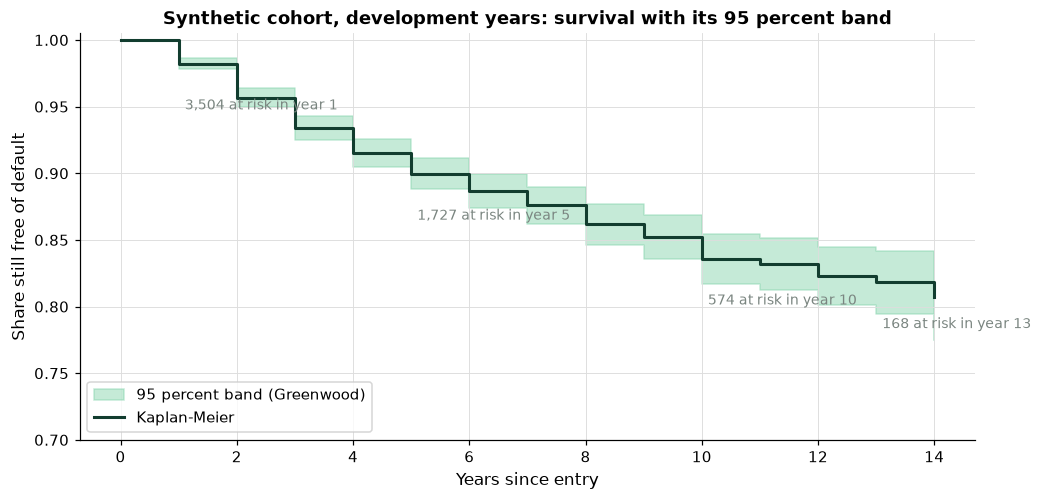

In [25]:
# the curve starts at 1 at year 0, with no uncertainty there
with_start = pd.concat([pd.DataFrame({"survival": [1.0], "standard error": [0.0]}, index=[0]), fitted[["survival", "standard error"]]])
band = 1.96 * with_start["standard error"]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.fill_between(with_start.index, with_start["survival"] - band, with_start["survival"] + band, step="post",
                color=plotkit.GREEN_LIGHT, alpha=0.45, label="95 percent band (Greenwood)")
ax.step(with_start.index, with_start["survival"], where="post", color=plotkit.GREEN_DARK, linewidth=2, label="Kaplan-Meier")
for t in [1, 5, 10, 13]:
    ax.annotate(f"{int(fitted.loc[t, 'at risk']):,} at risk in year {t}", xy=(t, fitted.loc[t, "survival"]), xytext=(4, -30),
                textcoords="offset points", ha="left", fontsize=9, color=plotkit.GREY)
ax.set_ylim(0.7, 1.005)
ax.set_xlabel("Years since entry")
ax.set_ylabel("Share still free of default")
ax.set_title("Synthetic cohort, development years: survival with its 95 percent band")
ax.legend(loc="lower left")
plt.show()

* How to read it: the curve starts at 1 and each step down is a year with defaults. The band is narrow in the early years, when thousands of firms are at risk, and fans out at the right, where a few hundred are left. The last steps of any survival curve rest on the fewest firms.

Q. Draw one curve per rating group at entry.

In [26]:
# one curve per rating group at entry, each with its own standard errors
group_order = ["investment grade", "BB", "B", "CCC"]
group_curves = {}
for name in group_order:
    members = firms[firms["group"] == name]
    group_curves[name] = SurvfuncRight(members["years"], members["defaulted"])
group_table = pd.DataFrame({
    "firms": [int((firms["group"] == name).sum()) for name in group_order],
    "defaults": [int(firms.loc[firms["group"] == name, "defaulted"].sum()) for name in group_order],
    "survival past 5 years": [float(group_curves[name].surv_prob[group_curves[name].surv_times <= 5][-1]) for name in group_order],
    "survival past 10 years": [float(group_curves[name].surv_prob[group_curves[name].surv_times <= 10][-1]) for name in group_order],
}, index=pd.Index(group_order, name="rating group at entry"))
print(group_table.round(4).to_string())

                       firms  defaults  survival past 5 years  survival past 10 years
rating group at entry                                                                
investment grade        1583        15                 0.9914                  0.9849
BB                       965        69                 0.9316                  0.8690
B                        721       149                 0.7787                  0.5842
CCC                      235       112                 0.3957                  0.2117


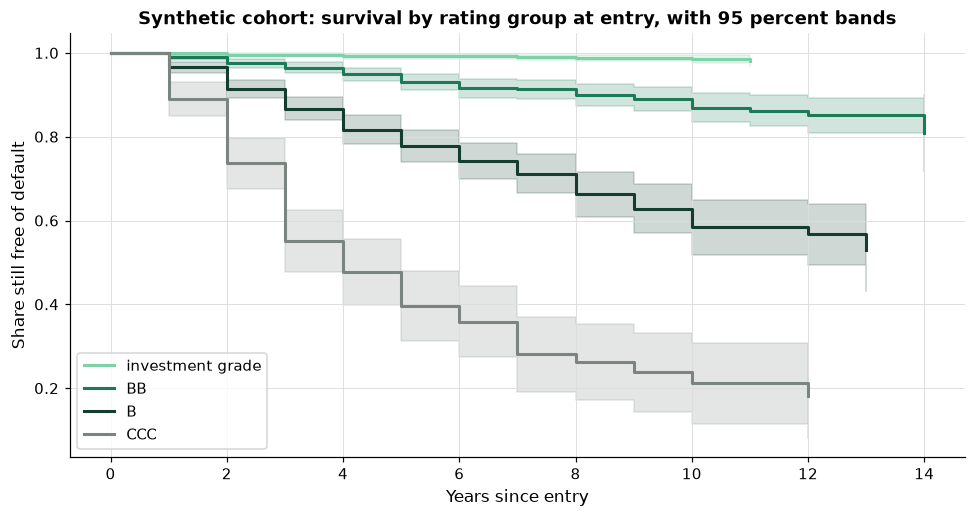

In [27]:
fig, ax = plt.subplots(figsize=(10.5, 5))
colours = {"investment grade": plotkit.GREEN_LIGHT, "BB": plotkit.GREEN, "B": plotkit.GREEN_DARK, "CCC": plotkit.GREY}
for name in group_order:
    curve = group_curves[name]
    # each curve starts at 1 at year 0
    times = np.concatenate([[0], curve.surv_times])
    survival = np.concatenate([[1.0], curve.surv_prob])
    band = 1.96 * np.concatenate([[0.0], curve.surv_prob_se])
    ax.fill_between(times, survival - band, survival + band, step="post", color=colours[name], alpha=0.2)
    ax.step(times, survival, where="post", color=colours[name], linewidth=2, label=name)
ax.set_xlabel("Years since entry")
ax.set_ylabel("Share still free of default")
ax.set_title("Synthetic cohort: survival by rating group at entry, with 95 percent bands")
ax.legend(loc="lower left")
plt.show()

In [28]:
plotkit.styled(group_table, ["survival past 10 years"], "Survival by rating group at entry, synthetic cohort, development years",
               fmt="{:,.4f}")

,firms,defaults,survival past 5 years,survival past 10 years
rating group at entry,,,,
investment grade,"1,583",15,0.9914,0.9849
BB,965,69,0.9316,0.8690
B,721,149,0.7787,0.5842
CCC,235,112,0.3957,0.2117


* The curves fan out in rating order: past 10 years, 98.5% of the investment grade firms are still free of default against 21.2% of the CCC firms. The investment grade curve rests on only 15 defaults, so its band is narrow because so many firms are at risk, not because its shape is well known.
* A firm's rating moves after entry, and this curve ignores that: it groups by the rating a firm entered with. Day 5's hazard models use each year's rating.

## 4.5 The Log-Rank Test

**How it works.** The **log-rank test** asks whether two or more survival curves differ by more than chance would make them. At each time with a default it compares the defaults each group had with the defaults it would have had if every group shared one curve, given who was at risk, and adds the gaps up into a chi-squared statistic. A small p-value says the curves differ. The test weighs every year alike; it can miss curves that cross. The setting is the grouping. What comes out is a chi-squared statistic and a p-value.

Q. Test all four groups, then three pairs of neighbouring buckets.

In [29]:
from statsmodels.duration.survfunc import survdiff

# the log-rank test: do these groups' curves differ by more than chance would make them?
def logrank_row(label, mask):
    chi_squared, p_value = survdiff(firms.loc[mask, "years"], firms.loc[mask, "defaulted"], firms.loc[mask, "group_or_bucket"])
    return {"comparison": label, "firms": int(mask.sum()), "defaults": int(firms.loc[mask, "defaulted"].sum()),
            "chi-squared": float(chi_squared), "p-value": float(p_value)}

firms["group_or_bucket"] = firms["group"]
logrank = [logrank_row("all four groups", firms["group"].notna())]
firms["group_or_bucket"] = firms["entry_bucket"]
logrank += [logrank_row("BB against B", firms["entry_bucket"].isin(["BB", "B"])),
            logrank_row("A against BBB", firms["entry_bucket"].isin(["A", "BBB"])),
            logrank_row("AA against A", firms["entry_bucket"].isin(["AA", "A"]))]
logrank = pd.DataFrame(logrank).set_index("comparison")
print(logrank.round(4).to_string())

                 firms  defaults  chi-squared  p-value
comparison                                            
all four groups   3504       345     960.8204   0.0000
BB against B      1686       218      90.7017   0.0000
A against BBB     1353        15       3.6684   0.0555
AA against A       680         2       0.8597   0.3538


In [30]:
plotkit.styled(logrank, ["p-value"], "Log-rank tests on the synthetic cohort's development years", fmt="{:,.4f}")

,firms,defaults,chi-squared,p-value
comparison,,,,
all four groups,"3,504",345,960.8204,0.0000
BB against B,"1,686",218,90.7017,0.0000
A against BBB,"1,353",15,3.6684,0.0555
AA against A,680,2,0.8597,0.3538


* The four groups differ beyond any doubt: a chi-squared of 961. BB against B is clear as well.
* AA against A gives a p-value of 0.3538: no evidence of a difference. That is not evidence that AA and A firms default alike: with 2 defaults between the two buckets, the test has almost nothing to work with. It is day 3's low-default problem again, in a test's words.

## 4.6 The Hazard and a Flat Hazard

**How it works.** The Kaplan-Meier table already holds the hazard: in each year, defaults over the firms at risk. Adding the hazards up gives the **cumulative hazard** (the Nelson-Aalen estimate), which for small hazards is close to minus the log of the survival curve. A **flat hazard** assumes the same h in every year, estimated as all the defaults over all the firm-years watched; its survival curve is exp(-h t). The setting is whether the hazard may change with time. What comes out is the year-by-year hazard, and a test of whether one number would have done.

Q. Compute the hazard and the cumulative hazard, year by year since entry.

In [31]:
# the hazard: the share of firms at risk at the start of a year that default in it, year by year since entry
hazard = pd.DataFrame({"at risk": km["at_risk"], "defaults": km["events"]})
hazard["hazard (percent a year)"] = 100 * hazard["defaults"] / hazard["at risk"]
# the cumulative hazard two ways: adding up the hazards (Nelson-Aalen), and minus the log of the survival curve
hazard["cumulative hazard, added up"] = (hazard["defaults"] / hazard["at risk"]).cumsum()
hazard["cumulative hazard, -ln S"] = -np.log(km["survival"])
print(hazard.round(4).to_string())

      at risk  defaults  hazard (percent a year)  cumulative hazard, added up  cumulative hazard, -ln S
time                                                                                                   
1.0      3504        62                   1.7694                       0.0177                    0.0179
2.0      2948        77                   2.6119                       0.0438                    0.0443
3.0      2496        59                   2.3638                       0.0675                    0.0682
4.0      2104        43                   2.0437                       0.0879                    0.0889
5.0      1727        29                   1.6792                       0.1047                    0.1058
6.0      1420        20                   1.4085                       0.1188                    0.1200
7.0      1139        14                   1.2291                       0.1311                    0.1324
8.0       915        15                   1.6393                

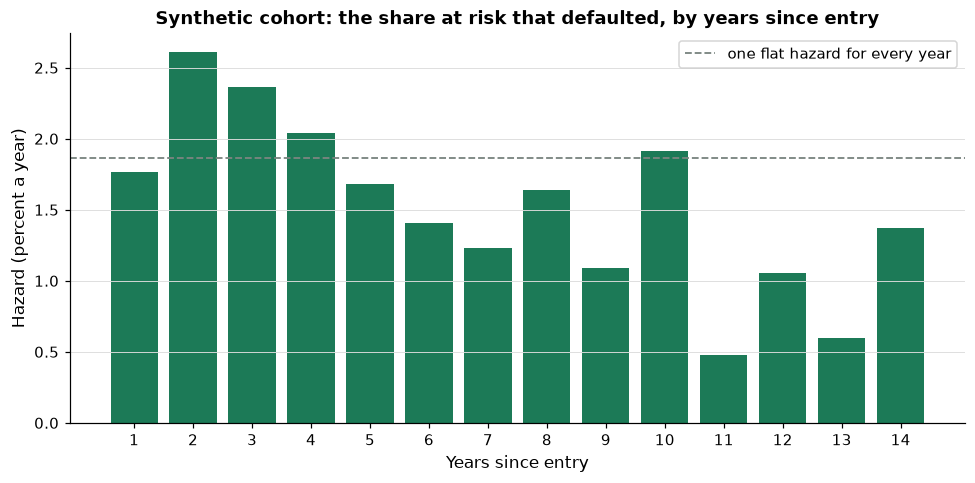

In [32]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.bar(hazard.index, hazard["hazard (percent a year)"], color=plotkit.GREEN)
ax.axhline(100 * hazard["defaults"].sum() / hazard["at risk"].sum(), color=plotkit.GREY, linestyle="--", linewidth=1.2,
           label="one flat hazard for every year")
ax.set_xticks(hazard.index)
ax.set_xlabel("Years since entry")
ax.set_ylabel("Hazard (percent a year)")
ax.set_title("Synthetic cohort: the share at risk that defaulted, by years since entry")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

* How to read it: the hazard is not flat. It rises from 1.77 percent in year 1 to 2.61 percent in year 2, then falls, to 1.64 percent by year 8. The later bars rest on fewer firms and jump about: year 10's 1.92 percent comes from 574 firms at risk. The cohort's generator adds a bump to the hazard in years 2 to 4 after entry (the coefficients are in the repo's `DATA.md`), and the bump shows. The fall after it has a second reason: the weakest firms default early, so the firms still at risk in later years are a stronger group.
* The two cumulative hazards agree closely: 0.1775 added up and 0.1792 as minus the log of the curve, at year 10.

Q. Set a flat hazard's curve beside Kaplan-Meier.

In [33]:
# one constant hazard for every year: all the defaults over all the firm-years watched
flat_hazard = firms["defaulted"].sum() / firms["years"].sum()
flat = pd.DataFrame({"Kaplan-Meier": km["survival"], "flat hazard, exp(-h t)": np.exp(-flat_hazard * km.index.to_numpy())})
flat["gap"] = flat["flat hazard, exp(-h t)"] - flat["Kaplan-Meier"]
print(f"flat hazard: {flat_hazard:.4%} a year, from {int(firms['defaulted'].sum())} defaults in {int(firms['years'].sum()):,} firm-years")
print(flat.loc[[2, 5, 10, 14]].round(4).to_string())

flat hazard: 1.8646% a year, from 345 defaults in 18,503 firm-years
      Kaplan-Meier  flat hazard, exp(-h t)     gap
time                                              
2.0         0.9566                  0.9634  0.0067
5.0         0.8996                  0.9110  0.0114
10.0        0.8359                  0.8299 -0.0060
14.0        0.8070                  0.7703 -0.0368


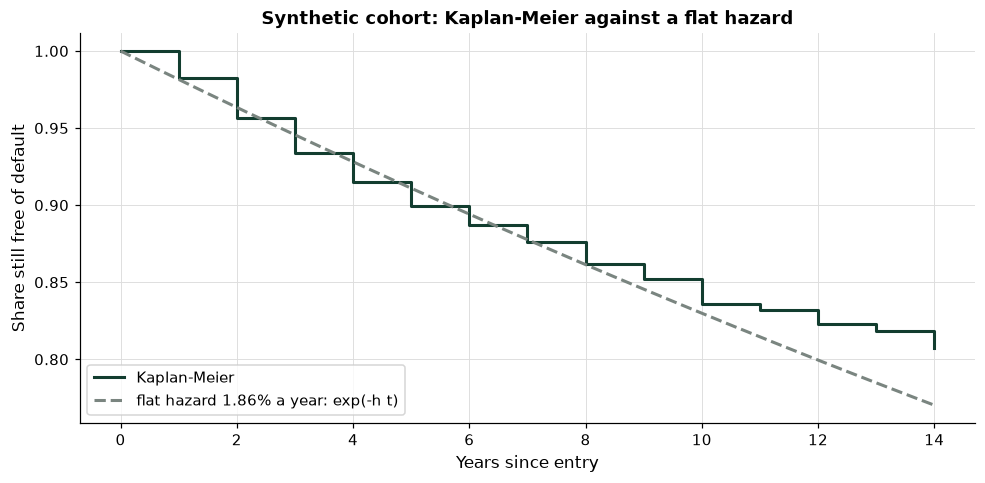

In [34]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.step(np.concatenate([[0], flat.index]), np.concatenate([[1.0], flat["Kaplan-Meier"]]), where="post",
        color=plotkit.GREEN_DARK, linewidth=2, label="Kaplan-Meier")
grid = np.linspace(0, 14, 200)
ax.plot(grid, np.exp(-flat_hazard * grid), color=plotkit.GREY, linestyle="--", linewidth=2,
        label=f"flat hazard {flat_hazard:.2%} a year: exp(-h t)")
ax.set_xlabel("Years since entry")
ax.set_ylabel("Share still free of default")
ax.set_title("Synthetic cohort: Kaplan-Meier against a flat hazard")
ax.legend(loc="lower left")
plt.show()

* The flat hazard is 1.86% a year: 345 defaults in 18,503 firm-years. Its curve is smooth and close to the real one, and it is wrong in the way the bars said: too high in the early years, when the real hazard runs above the flat one, and too low later. The largest gap is -0.0368 at year 14. One number is a fair summary of 14 years; it is not a fair description of any one of them.

## 4.7 The Credit Triangle

**How it works.** A constant hazard links the default world to the spread world. If a bond pays a spread s over the risk-free rate, defaults at a constant hazard h, and recovers R of its value on default, then to first order the spread pays for the expected loss: s = h x (1 - R). Turned around, h = s / (1 - R): the **credit triangle**, a published identity. The settings are the spread and the recovery rate. What comes out is a hazard, and from it, with exp(-h t), a survival curve. It is arithmetic: a spread holds more than expected loss (it also pays investors for bearing the risk), so a hazard read off a spread is a different quantity from the cohort's counted one.

Q. Turn three invented spreads into hazards and 5-year default chances, with a recovery rate of 40 percent.

In [35]:
# the credit triangle on invented numbers: a constant hazard h = spread / (1 - recovery), then survival exp(-h t)
RECOVERY = 0.40
triangle = pd.DataFrame({"spread (bp)": [100, 250, 500]})
triangle["hazard (percent a year)"] = 100 * (triangle["spread (bp)"] / 10_000) / (1 - RECOVERY)
triangle["survival past 5 years"] = np.exp(-5 * triangle["hazard (percent a year)"] / 100)
triangle["default within 5 years"] = 1 - triangle["survival past 5 years"]
triangle = triangle.set_index("spread (bp)")
print(triangle.round(4).to_string())

             hazard (percent a year)  survival past 5 years  default within 5 years
spread (bp)                                                                        
100                           1.6667                 0.9200                  0.0800
250                           4.1667                 0.8119                  0.1881
500                           8.3333                 0.6592                  0.3408


In [36]:
plotkit.styled(triangle, ["default within 5 years"], "The credit triangle on invented spreads, recovery 40 percent: "
               "h = s / (1 - R) and survival exp(-5h)", fmt="{:,.4f}")

,hazard (percent a year),survival past 5 years,default within 5 years
spread (bp),,,
100,1.6667,0.9200,0.0800
250,4.1667,0.8119,0.1881
500,8.3333,0.6592,0.3408


* An invented spread of 250 bp with 40 percent recovery gives a hazard of 4.17 percent a year and a 18.8% chance of default within 5 years. The numbers are invented, so the table says nothing about any bond; it shows how the arithmetic runs.

## A Story: Two Manuscripts, One Paper

Edward Kaplan and Paul Meier were both graduate students in mathematics at Princeton with the same advisor, John Tukey, and each worked separately on survival from incomplete observations. Kaplan later told the story: "This paper began in 1952 when Paul Meier at Johns Hopkins University ... encountered Greenwood's paper on the duration of cancer. A year later at Bell Telephone Laboratories, I became interested in the lifetimes of vacuum tubes in the repeaters in telephone cables buried in the ocean." Both sent manuscripts to the *Journal of the American Statistical Association*, "which recommended a joint paper. Much correspondence over four years was required to reconcile our differing approaches." The joint paper appeared in June 1958. Stalpers and Kaplan report that with 44,319 Web of Science citations as of November 2017 it had become "the most-cited statistics publication in the scientific literature".

The point for a desk: the method was built for patients and for vacuum tubes, two things watched until they failed or the watch ended. A book of bonds is a third.

Sources: L. J. A. Stalpers and E. L. Kaplan, "Edward L. Kaplan and the Kaplan-Meier Survival Curve", *BSHM Bulletin: Journal of the British Society for the History of Mathematics* 33 (2), 2018, pages 109 to 111, https://doi.org/10.1080/17498430.2018.1450055 , quoting Kaplan in E. Garfield, *Current Contents*, 1983; E. L. Kaplan and P. Meier, "Nonparametric Estimation from Incomplete Observations", *Journal of the American Statistical Association* 53 (282), 1958, pages 457 to 481.

## Excel Side by Side

Kaplan-Meier is a table Excel builds well: one row per distinct time, `COUNTIF` for the firms at risk, `COUNTIFS` for the defaults, and a running product. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-24). The check pasted the ten firms of section 4.2 into A2:B11 (years, defaulted), their 5 distinct times into D2:D6, and all 3,504 firms into K2:L3505.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Excel returned</th></tr>
<tr><td align="left">Firms at risk at a time</td><td align="left"><code>(ten["years"] &gt;= t).sum()</code></td><td align="left"><code>=COUNTIF($A$2:$A$11,"&gt;="&amp;D2)</code></td><td align="left">equal on every row</td></tr>
<tr><td align="left">Defaults at a time</td><td align="left"><code>((ten["years"] == t) &amp; (ten["defaulted"] == 1)).sum()</code></td><td align="left"><code>=COUNTIFS($A$2:$A$11,D2,$B$2:$B$11,1)</code></td><td align="left">equal on every row</td></tr>
<tr><td align="left">The first row of the curve</td><td align="left"><code>1 - defaults / at_risk</code></td><td align="left"><code>=1-F2/E2</code></td><td align="left"></td></tr>
<tr><td align="left">Every later row: the running product</td><td align="left"><code>np.cumprod(1 - defaults / at_risk)</code></td><td align="left"><code>=G2*(1-F3/E3)</code></td><td align="left">equal within 1e-12 on every row</td></tr>
<tr><td align="left">The flat hazard</td><td align="left"><code>firms["defaulted"].sum() / firms["years"].sum()</code></td><td align="left"><code>=SUM(L2:L3505)/SUM(K2:K3505)</code></td><td align="left">0.018646</td></tr>
<tr><td align="left">Survival past 10 years at that hazard</td><td align="left"><code>np.exp(-flat_hazard * 10)</code></td><td align="left"><code>=EXP(-N1*10)</code></td><td align="left">0.829895</td></tr>
<tr><td align="left">The credit triangle at 250 bp, recovery 40%</td><td align="left"><code>0.025 / (1 - 0.40)</code></td><td align="left"><code>=0.025/(1-0.4)</code></td><td align="left">0.041667</td></tr>
<tr><td align="left">Default within 5 years at that hazard</td><td align="left"><code>1 - np.exp(-5 * h)</code></td><td align="left"><code>=1-EXP(-5*N3)</code></td><td align="left">0.188064</td></tr>
</table>
<br clear="left">

**The table.** `COUNTIF($A$2:$A$11,">="&D2)` counts the firms watched for at least the row's years: the at-risk column, with the threshold joined by `&` as on day 2. `COUNTIFS` takes two conditions, the time and the default flag. The survival column starts with `1-F2/E2` and every later row multiplies the row above by its own share, which is the running product.

**One number.** The flat hazard is two `SUM`s, and `EXP(-h*t)` its curve, the same `EXP` as `=EXP(-h*t)` for survival at a flat hazard anywhere. Excel has no Kaplan-Meier function, no Greenwood band, and no log-rank test; the table above is the way to build the curve by hand.

In [37]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [0.018645625033778306, 0.829894868777319, 0.04166666666666667, 0.18806365384936508, 0.5],
    "Python": [flat_hazard, np.exp(-flat_hazard * 10), triangle.loc[250, "hazard (percent a year)"] / 100,
               triangle.loc[250, "default within 5 years"], hand["survival"].iloc[-1]],
}, index=pd.Index(["flat hazard", "survival past 10 years, flat", "credit triangle hazard at 250 bp",
                    "default within 5 years at that hazard", "ten firms: the curve's last value"], name="Check"))
excel_side["equal within 1e-9"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-9
plotkit.styled(excel_side, [], "Excel beside Python on the hand table, the flat hazard, and the credit triangle", fmt="{:,.6f}")

,Excel,Python,equal within 1e-9
Check,,,
flat hazard,0.018646,0.018646,True
"survival past 10 years, flat",0.829895,0.829895,True
credit triangle hazard at 250 bp,0.041667,0.041667,True
default within 5 years at that hazard,0.188064,0.188064,True
ten firms: the curve's last value,0.500000,0.500000,True


* Every value is equal within 1e-9, and the at-risk, default, and survival columns of the hand table matched on every row.

## Save the Day with Git

Today's Git step reads a commit back. `git show HEAD:riskkit.py` prints a file exactly as the last commit holds it, without touching the copy in the folder, so you can check what was saved.

Q. Start a repository in the work folder, tell Git which files never to track, and commit the code.

In [38]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [39]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5c_04_ko9w2c_0 and nowhere else


In [40]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [41]:
!git -C "{work}" add .gitignore mlkit.py riskkit.py test_riskkit.py
!git -C "{work}" commit -q -m "Day 4: riskkit with kaplan_meier"
!git -C "{work}" log --oneline

8785632 Day 4: riskkit with kaplan_meier


Q. Read today's function back from the commit.

In [42]:
# git show prints the committed file; keep the lines from today's function on
shown = subprocess.run(["git", "-C", str(work), "show", "HEAD:riskkit.py"], capture_output=True, text=True, check=True).stdout
print(shown[shown.index("def kaplan_meier"):].split("\n\n\n")[0].split('"""')[0] + '"""...')
print(f"the committed file is the file in the folder: {shown == (work / 'riskkit.py').read_text(encoding='utf-8')}")

def kaplan_meier(time, event):
    """...
the committed file is the file in the folder: True


## Bring It Home

Add today's function to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `riskkit.py` and paste the code of today's `riskkit.py` cell (section 4.2) at the end, without its first line. Do the same for the `test_riskkit.py` cell in `test_riskkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_riskkit.py
```

The last line says `21 passed`.

**Step 4.** Commit.

```powershell
git add riskkit.py test_riskkit.py
git commit -m "Day 4: riskkit with kaplan_meier"
```

## You Can Now

* Turn firm-year rows into one row per firm, and say which endings are censored.
* Work Kaplan-Meier by hand and with `kaplan_meier`, and say why a censored firm counts as at risk until it leaves.
* Show the bias of dropping censored firms (62.5% past 10 years) and of counting them as survivors (90.4%) against Kaplan-Meier's 83.6%.
* Fit a curve with `SurvfuncRight`, read its Greenwood band, and draw curves by rating.
* Run a log-rank test, and say why a high p-value on few defaults proves nothing.
* Read the hazard year by year, the cumulative hazard, and a flat hazard's curve.
* Turn a spread and a recovery rate into a hazard with the credit triangle.

Next, day 5: a case study with hazard models, where each firm's own leverage, coverage, and rating enter the hazard.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the cohort's development years, builds one row per firm as in section 4.1, and defines `check`, a small function that marks your answers.

In [43]:
from statsmodels.duration.survfunc import SurvfuncRight, survdiff

# the synthetic cohort: invented firms with ids only, in study years; the development years 1 to 14 only
cohort = pd.read_csv("course5c_cohort.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END]

# one row per firm: the years it was watched, how its last year ended, and its rating when it entered
firms = development.groupby("firm_id").agg(years=("years_since_entry", "max"), defaulted=("default", "max"),
                                           exited=("exit", "max"), entry_rating=("rating", "first"))
GROUPS = {"AAA": "investment grade", "AA": "investment grade", "A": "investment grade", "BBB": "investment grade",
          "BB": "BB", "B": "B", "CCC": "CCC"}
firms["entry_bucket"] = firms["entry_rating"].map(ratings["bucket"])
firms["group"] = firms["entry_bucket"].map(GROUPS)
print(f"{len(firms):,} invented firms entered by study year {DEVELOPMENT_END}")
print(firms.head().to_string())


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

3,504 invented firms entered by study year 14
         years  defaulted  exited entry_rating entry_bucket             group
firm_id                                                                      
F0001        9          0       1           BB           BB                BB
F0002        2          1       0            B            B                 B
F0003       14          0       0          AA-           AA  investment grade
F0004        4          0       1           B+            B                 B
F0005       14          0       0           A-            A  investment grade


### Exercise 1

Q. What share of the firms that entered with a B rating (`entry_bucket == "B"`) were still free of default past 5 years? Use `riskkit.kaplan_meier`, and store the value in **ex1_survival_5**.

In [44]:
ex1_survival_5 = ...

In [45]:
check("Exercise 1 B survival past 5 years", ex1_survival_5, 0.7787257175055496)

Exercise 1 B survival past 5 years: not attempted yet


### Exercise 2

Q. With the credit triangle, an invented spread of 400 bp and a recovery rate of 40 percent: what is the chance of default within 5 years? Store it in **ex2_default_5**.

In [46]:
ex2_default_5 = ...

In [47]:
check("Exercise 2 default within 5 years from the triangle", ex2_default_5, 0.28346868942621073)

Exercise 2 default within 5 years from the triangle: not attempted yet


### Exercise 3

Q. Add a function to your module. `nelson_aalen(time, event)` returns the cumulative hazard at each distinct time: the running sum of events over at risk. Build it on `kaplan_meier`, so it has the same inputs and refusals. Write the docstring first. Add `test_nelson_aalen_hand`, which checks the six subjects of `test_kaplan_meier_hand` give 1/6, 1/6, 1/6 + 1/4, and 1/6 + 1/4. Run pytest, reload the module, and store the cohort's cumulative hazard at 10 years in **ex3_cumulative_10**.

Write the function in the cell that starts with `%%writefile -a riskkit.py` and the test in the one that starts with `%%writefile -a test_riskkit.py`, and run each of those cells once.

In [48]:
%%writefile -a riskkit.py


# Exercise 3: write nelson_aalen(time, event) below this line

Appending to riskkit.py


In [49]:
%%writefile -a test_riskkit.py


# Exercise 3: write test_nelson_aalen_hand() below this line

Appending to test_riskkit.py


In [50]:
# run pytest, reload the module, then use your function
ex3_cumulative_10 = ...

In [51]:
check("Exercise 3 cumulative hazard at 10 years", ex3_cumulative_10, 0.17749822508521526)

Exercise 3 cumulative hazard at 10 years: not attempted yet


### Exercise 4

Q. Run the log-rank test on the firms that entered as A or as BBB, grouped by `entry_bucket`, with `survdiff`. Store the p-value in **ex4_p_value**. What does it say, and what does it not say?

In [52]:
ex4_p_value = ...

In [53]:
check("Exercise 4 log-rank p-value, A against BBB", ex4_p_value, 0.05545222415803974)

Exercise 4 log-rank p-value, A against BBB: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that turns firm-year rows into one row per firm for a survival curve, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
One row per firm, from firm-year rows: the years it was watched and whether it defaulted.

    rows has one row per firm and study year, with the columns firm_id, years_since_entry, default, and exit.
    A firm's time is its last years_since_entry. Its event is 1 if its watch ended in a default; a firm that
    exited, or was still at risk at the end, is censored: event 0.
    Returns a DataFrame indexed by firm_id with the columns time and event.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns one row per firm, and contains one bug.

In [54]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def firm_outcomes(rows):
    """One row per firm, from firm-year rows: the years it was watched and whether it defaulted.

    rows has one row per firm and study year, with the columns firm_id, years_since_entry, default, and exit.
    A firm's time is its last years_since_entry. Its event is 1 if its watch ended in a default; a firm that
    exited, or was still at risk at the end, is censored: event 0.
    Returns a DataFrame indexed by firm_id with the columns time and event.
    """
    last = rows.groupby("firm_id").agg(time=("years_since_entry", "max"), default=("default", "max"),
                                       exit=("exit", "max"))
    # a firm whose watch ended early has an event
    last["event"] = ((last["default"] == 1) | (last["exit"] == 1)).astype(int)
    return last[["time", "event"]]

Q. Before you run the next cell: how many events should the function give, if each event is a default? How many does it give?

In [55]:
outcomes_bad = firm_outcomes(development)
print(f"defaults in the rows: {int(development['default'].sum())}; events from the function: {int(outcomes_bad['event'].sum())}")

defaults in the rows: 345; events from the function: 1576


Q. Test the function against its docstring before you trust it: every default is one firm's event, and nothing else is.

In [56]:
# the test, written from the docstring before the code is trusted
outcomes_check = firm_outcomes(development)
# every default in the rows is one firm's event, and nothing else is
assert outcomes_check["event"].sum() == development["default"].sum(), (
    f"{outcomes_check['event'].sum()} events from {development['default'].sum()} defaults: something else is counted as a default")
print(f"{int(outcomes_check['event'].sum())} events, one per default")

AssertionError: 1576 events from 345 defaults: something else is counted as a default

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store survival past 10 years from the fixed function's firms, `float(riskkit.kaplan_meier(outcomes_check["time"], outcomes_check["event"])["survival"].loc[10])`, in **ex5_survival_10**.

In [57]:
# fix the function above and run the test again, then store the answer
ex5_survival_10 = ...

In [58]:
check("Exercise 5 survival past 10 years, fixed function", ex5_survival_10, 0.8359388586228113)

Exercise 5 survival past 10 years, fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```